# Chapter 22: Derivatives with vectors and matrices

The code for this chapter from [*Matrices in Practice*](https://trgoodale.github.io/matrix-book/part-4/22-matrix-calculus.html), by Tom Goodale.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/trgoodale/matrix-book/blob/main/code/python/22-matrix-calculus.ipynb)

Run the cells in order, from the top: later cells use variables set in earlier ones. Change the numbers and run them again to see what happens. The code needs NumPy, SciPy and Matplotlib (and pandas in a few chapters), all of which Colab already has.

Code licensed under the [MIT licence](https://trgoodale.github.io/matrix-book/LICENSE.md).

### Code for Figure 22.1

This draws [Figure 22.1](https://trgoodale.github.io/matrix-book/part-4/22-matrix-calculus.html#fig-gradient-descent) in the chapter. You don't need it for the rest of the notebook.

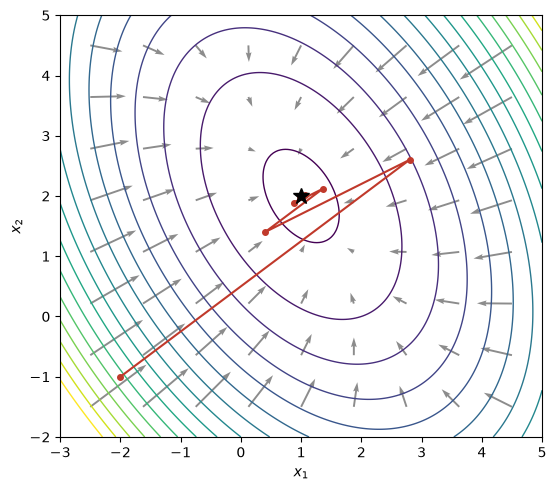

In [1]:
import numpy as np
import matplotlib.pyplot as plt

A = np.array([[3.0, 1.0], [1.0, 2.0]])
b = np.array([5.0, 5.0])
f = lambda x, y: 0.5 * (A[0, 0] * x**2 + 2 * A[0, 1] * x * y + A[1, 1] * y**2) - b[0] * x - b[1] * y

x, y = np.meshgrid(np.linspace(-3, 5, 200), np.linspace(-2, 5, 200))
fig, ax = plt.subplots(figsize=(6, 5))
ax.contour(x, y, f(x, y), levels=np.arange(-7, 40, 3), cmap="viridis", linewidths=1)

gx, gy = np.meshgrid(np.linspace(-2.5, 4.5, 9), np.linspace(-1.5, 4.5, 8))
grad = np.einsum("ij,jkl->ikl", A, np.array([gx, gy])) - b[:, None, None]
ax.quiver(gx, gy, -grad[0], -grad[1], color="0.55", angles="xy", scale=120, width=0.004)

path = [np.array([-2.0, -1.0])]
for _ in range(20):
    path.append(path[-1] - 0.4 * (A @ path[-1] - b))
path = np.array(path)
ax.plot(path[:, 0], path[:, 1], "o-", color="#c0392b", ms=4, lw=1.5)
ax.plot(1, 2, "k*", ms=12)
ax.set_aspect("equal")
ax.set_xlabel("$x_1$")
ax.set_ylabel("$x_2$")
plt.tight_layout()
plt.show()

## In code

Getting gradients right by hand is error-prone, so it is worth checking them numerically: compare each entry with a **finite difference** $(f(\mathbf{x} + h\mathbf{e}_{i}) - f(\mathbf{x} - h\mathbf{e}_{i}))/(2h)$ for a small $h$. In Python, the SymPy package (`pip install sympy`) can also find gradients, Jacobians and Hessians symbolically, as can MATLAB's Symbolic Math Toolbox with `gradient`, `jacobian` and `hessian`.

In [2]:
import numpy as np

A = np.array([[3.0, 1.0], [1.0, 2.0]])
b = np.array([5.0, 5.0])
f = lambda x: 0.5 * x @ A @ x - b @ x
grad = lambda x: A @ x - b

# Check the gradient by central differences
x = np.array([-2.0, -1.0])
h = 1e-6
fd = np.array([(f(x + h * e) - f(x - h * e)) / (2 * h) for e in np.eye(2)])
print(grad(x), fd)

# Gradient descent
for k in range(19):
    x = x - 0.4 * grad(x)
print(x)                                   # close to (1, 2)

[-12.  -9.] [-12.  -9.]
[1.00000092 2.00000031]


In [3]:
import sympy as sp

x, y, r, t = sp.symbols("x y r theta")
f = x**3 - 3*x + y**2
print(sp.hessian(f, (x, y)))
print(sp.solve([sp.diff(f, x), sp.diff(f, y)], [x, y]))

J = sp.Matrix([r*sp.cos(t), r*sp.sin(t)]).jacobian([r, t])
print(J, sp.simplify(J.det()))

Matrix([[6*x, 0], [0, 2]])


[(-1, 0), (1, 0)]
Matrix([[cos(theta), -r*sin(theta)], [sin(theta), r*cos(theta)]]) r


## Exercises

The code exercises from the [end of the chapter](https://trgoodale.github.io/matrix-book/part-4/22-matrix-calculus.html#sec-matrix-calculus-exercises). Worked solutions are in the notebook `solutions-part-4.ipynb`, and in the [book's solutions](https://trgoodale.github.io/matrix-book/appendices/solutions-4.html#sec-solutions-matrix-calculus).

### Exercise 7

Use gradient descent to minimise $f(\mathbf{x}) = \tfrac{1}{2}\mathbf{x}^{\mathsf{T}}\mathbf{A}\mathbf{x}$ with $\mathbf{A} = \begin{pmatrix}10 & 0 \\ 0 & 1\end{pmatrix}$, starting from $(1, 1)$, with step sizes $\alpha = 0.1$, $0.18$ and $0.21$. For each, count the steps until $\lVert\mathbf{x}\rVert < 10^{-6}$, or report that it fails. Explain the results using the eigenvalues of $\mathbf{A}$.

In [4]:
# Your code here